Name - Vanshika Chauhan

Course - B Tech CSE (3rd year)

Subject - Computer Vision

CuId - CU240250953

# Lab Sheet 5 — SIFT and HOG Feature Descriptor

In [ ]:
# Cell 1 — Install/import required libraries
!pip -q install opencv-python-headless scikit-image matplotlib pandas

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from skimage import data, color, transform, exposure
from skimage.feature import hog
from google.colab import files

plt.rcParams["figure.figsize"] = (10, 6)
print("OpenCV:", cv2.__version__)
print("Libraries imported successfully.")


OpenCV: 4.14.0
Libraries imported successfully.


## 1. Build a SIFT keypoint detector and visualizer


Number of SIFT keypoints: 1105
Descriptor shape: (1105, 128)


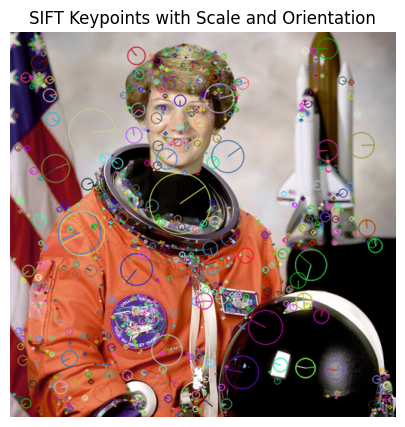

In [ ]:
img = data.astronaut()
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

sift = cv2.SIFT_create()
keypoints, descriptors = sift.detectAndCompute(gray, None)

result = cv2.drawKeypoints(
    img, keypoints, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

print("Number of SIFT keypoints:", len(keypoints))
print("Descriptor shape:", descriptors.shape if descriptors is not None else None)

plt.figure(figsize=(10, 5))
plt.imshow(result)
plt.axis("off")
plt.title("SIFT Keypoints with Scale and Orientation")
plt.show()


## 2. Image matching using SIFT descriptors

Keypoints image 1: 1105
Keypoints image 2: 1068
Good matches: 716


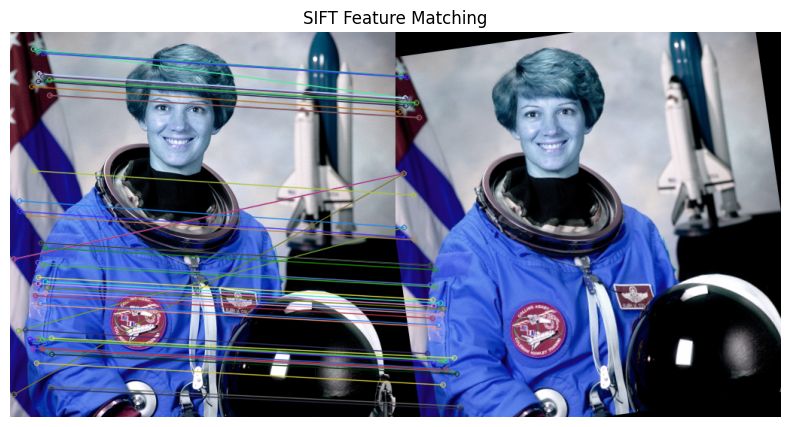

In [ ]:
img1 = data.astronaut()
h, w = img1.shape[:2]

# Create a second view using rotation + scaling
M = cv2.getRotationMatrix2D((w//2, h//2), 8, 1.0)
img2 = cv2.warpAffine(img1, M, (w, h))

g1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)
g2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY)

sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(g1, None)
kp2, des2 = sift.detectAndCompute(g2, None)

bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

# Lowe's ratio test
good = [m for m, n in matches if m.distance < 0.75 * n.distance]

matched_img = cv2.drawMatches(
    img1, kp1, img2, kp2, good[:50], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

print("Keypoints image 1:", len(kp1))
print("Keypoints image 2:", len(kp2))
print("Good matches:", len(good))

plt.figure(figsize=(14, 5))
plt.imshow(cv2.cvtColor(matched_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("SIFT Feature Matching")
plt.show()


## 3. Simple panorama stitching using SIFT and homography


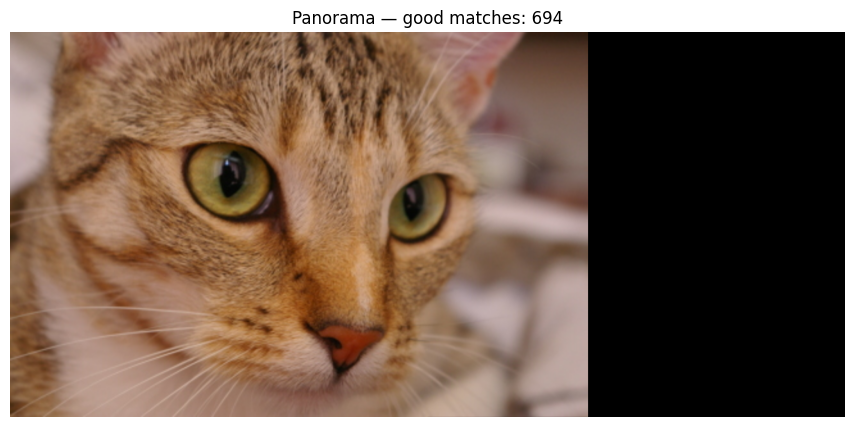

In [ ]:
base = data.chelsea()  # cat image with enough visual features
base = cv2.resize(base, (900, 600))

# Create two overlapping views
left = base[:, :650]
right = base[:, 250:]

gray1 = cv2.cvtColor(left, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(right, cv2.COLOR_RGB2GRAY)

sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)

bf = cv2.BFMatcher()
raw_matches = bf.knnMatch(des2, des1, k=2)
good = [m for m, n in raw_matches if m.distance < 0.75*n.distance]

if len(good) >= 4:
    src_pts = np.float32([kp2[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp1[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

    canvas_w = left.shape[1] + right.shape[1]
    canvas_h = max(left.shape[0], right.shape[0])
    panorama = cv2.warpPerspective(right, H, (canvas_w, canvas_h))
    panorama[:left.shape[0], :left.shape[1]] = left

    plt.figure(figsize=(12, 5))
    plt.imshow(panorama)
    plt.axis("off")
    plt.title(f"Panorama — good matches: {len(good)}")
    plt.show()
else:
    print("Not enough good matches to estimate homography.")


## 4. Logo/object locator using SIFT feature matching
A reference object is placed inside a larger cluttered image. SIFT matching estimates where the reference occurs.

Good matches: 187


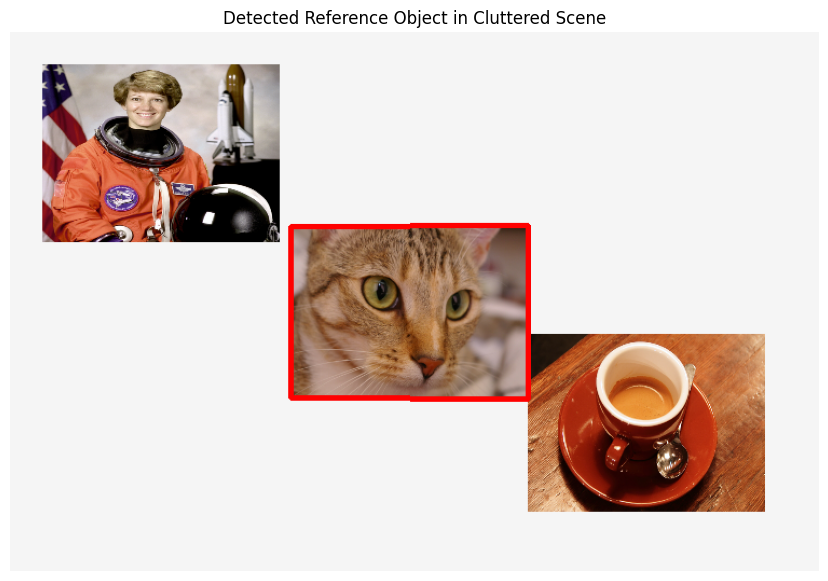

In [ ]:
reference = data.chelsea()
reference = cv2.resize(reference, (220, 160))

# Use a textured crop as the reference object
ref_gray = cv2.cvtColor(reference, cv2.COLOR_RGB2GRAY)

scene = np.ones((500, 750, 3), dtype=np.uint8) * 245

# Add several distractor images
d1 = cv2.resize(data.astronaut(), (220, 165))
d2 = cv2.resize(data.coffee(), (220, 165))
scene[30:195, 30:250] = d1
scene[280:445, 480:700] = d2

# Put the reference object into the cluttered scene
scene[180:340, 260:480] = reference

sift = cv2.SIFT_create()
kp_ref, des_ref = sift.detectAndCompute(ref_gray, None)
kp_scene, des_scene = sift.detectAndCompute(
    cv2.cvtColor(scene, cv2.COLOR_RGB2GRAY), None
)

bf = cv2.BFMatcher()
matches = bf.knnMatch(des_ref, des_scene, k=2)
good = [m for m, n in matches if m.distance < 0.72*n.distance]

print("Good matches:", len(good))

if len(good) >= 4:
    src = np.float32([kp_ref[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_scene[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)

    if H is not None:
        rh, rw = reference.shape[:2]
        corners = np.float32([[0,0], [rw,0], [rw,rh], [0,rh]]).reshape(-1,1,2)
        projected = cv2.perspectiveTransform(corners, H)

        output = scene.copy()
        cv2.polylines(output, [np.int32(projected)], True, (255, 0, 0), 4)

        plt.figure(figsize=(12, 7))
        plt.imshow(output)
        plt.axis("off")
        plt.title("Detected Reference Object in Cluttered Scene")
        plt.show()
    else:
        print("Homography could not be estimated.")
else:
    print("Not enough matches.")


## 5. HOG-based pedestrian/person detector
OpenCV's built-in HOG + SVM pedestrian detector is used. The notebook also provides an upload option for a real pedestrian image.

Detections on built-in sample: 1


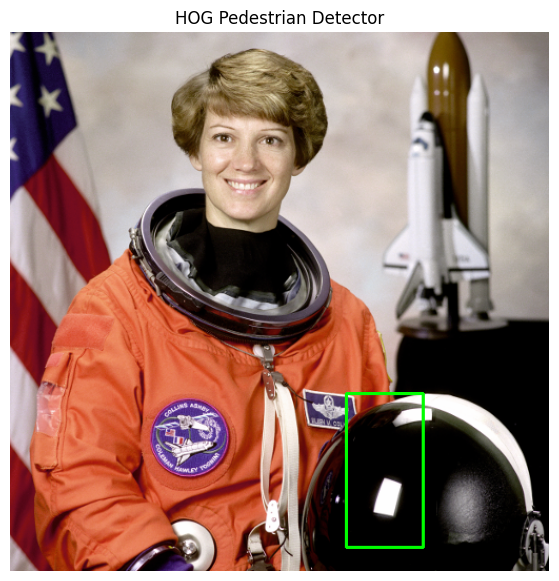

For a real pedestrian photo, use the optional upload cell below.


In [ ]:
# Built-in OpenCV people detector
hog_detector = cv2.HOGDescriptor()
hog_detector.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())

# Built-in sample image
sample = data.astronaut()
sample_bgr = cv2.cvtColor(sample, cv2.COLOR_RGB2BGR)

boxes, weights = hog_detector.detectMultiScale(
    sample_bgr,
    winStride=(8, 8),
    padding=(8, 8),
    scale=1.05
)

detected = sample.copy()
for (x, y, w, h), weight in zip(boxes, weights):
    cv2.rectangle(detected, (x, y), (x+w, y+h), (0, 255, 0), 2)

print("Detections on built-in sample:", len(boxes))
plt.figure(figsize=(10, 7))
plt.imshow(detected)
plt.axis("off")
plt.title("HOG Pedestrian Detector")
plt.show()

print("For a real pedestrian photo, use the optional upload cell below.")


Saving flower.jpeg to flower (1).jpeg


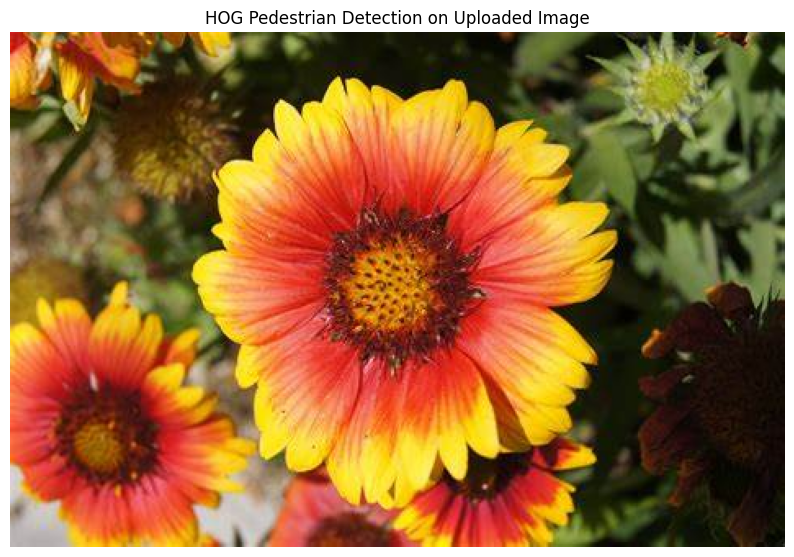

In [ ]:
uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    user_img = cv2.imread(filename)

    boxes, weights = hog_detector.detectMultiScale(
        user_img,
        winStride=(8, 8),
        padding=(8, 8),
        scale=1.05
    )

    output = user_img.copy()
    for (x, y, w, h), weight in zip(boxes, weights):
        cv2.rectangle(output, (x, y), (x+w, y+h), (0, 255, 0), 2)

    plt.figure(figsize=(10, 7))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("HOG Pedestrian Detection on Uploaded Image")
    plt.show()


## 6. HOG visualizer
Compute HOG features and overlay the gradient-orientation information on an image.

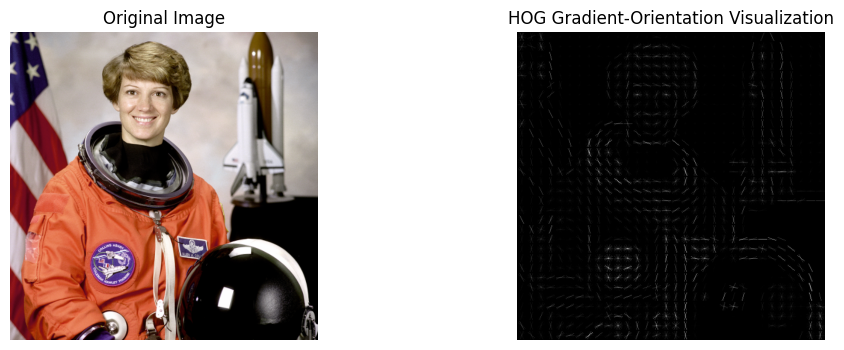

HOG descriptor length: 34596


In [ ]:
img = data.astronaut()
gray = color.rgb2gray(img)

# HOG visualization image
features, hog_image = hog(
    gray,
    orientations=9,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2),
    visualize=True,
    block_norm="L2-Hys"
)

hog_image = exposure.rescale_intensity(hog_image, in_range=(0, 10))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(img)
ax[0].axis("off")
ax[0].set_title("Original Image")

ax[1].imshow(hog_image, cmap="gray")
ax[1].axis("off")
ax[1].set_title("HOG Gradient-Orientation Visualization")

plt.show()
print("HOG descriptor length:", len(features))


## 7. Duplicate / near-duplicate image detector using SIFT similarity scoring


Keypoints image A: 1105
Keypoints image B: 1058
SIFT similarity score: 0.6578
Result: Likely duplicate / near-duplicate


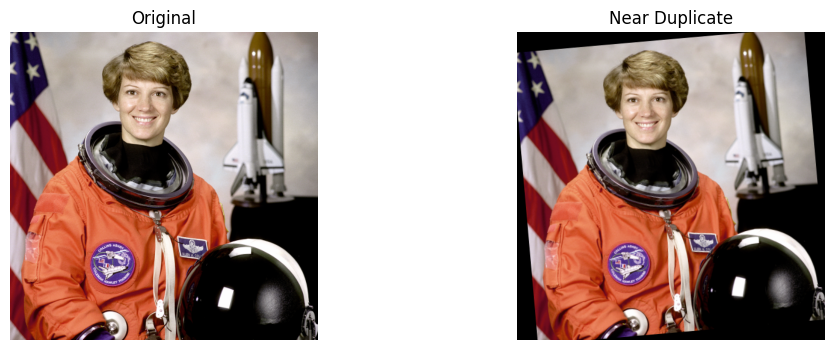

In [ ]:
original = data.astronaut()
h, w = original.shape[:2]

M = cv2.getRotationMatrix2D((w//2, h//2), 5, 0.95)
near_duplicate = cv2.warpAffine(original, M, (w, h))

def sift_similarity(img_a, img_b, ratio=0.75):
    a = cv2.cvtColor(img_a, cv2.COLOR_RGB2GRAY)
    b = cv2.cvtColor(img_b, cv2.COLOR_RGB2GRAY)

    sift = cv2.SIFT_create()
    kpa, desa = sift.detectAndCompute(a, None)
    kpb, desb = sift.detectAndCompute(b, None)

    if desa is None or desb is None:
        return 0, 0, 0

    matcher = cv2.BFMatcher()
    matches = matcher.knnMatch(desa, desb, k=2)
    good = [m for m, n in matches if m.distance < ratio*n.distance]

    score = len(good) / max(1, min(len(kpa), len(kpb)))
    return len(kpa), len(kpb), score

ka, kb, score = sift_similarity(original, near_duplicate)

print("Keypoints image A:", ka)
print("Keypoints image B:", kb)
print("SIFT similarity score:", round(score, 4))

threshold = 0.15
print("Result:", "Likely duplicate / near-duplicate" if score >= threshold else "Likely different image")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(original); ax[0].axis("off"); ax[0].set_title("Original")
ax[1].imshow(near_duplicate); ax[1].axis("off"); ax[1].set_title("Near Duplicate")
plt.show()


## 8. Robustness / scale-invariance test for SIFT


In [ ]:
# Experiment 8 — SIFT invariance test
original = data.astronaut()
gray_original = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

sift = cv2.SIFT_create()
kp0, des0 = sift.detectAndCompute(gray_original, None)

def count_good_matches(img_a, img_b):
    ga = cv2.cvtColor(img_a, cv2.COLOR_RGB2GRAY)
    gb = cv2.cvtColor(img_b, cv2.COLOR_RGB2GRAY)

    kpa, desa = sift.detectAndCompute(ga, None)
    kpb, desb = sift.detectAndCompute(gb, None)

    if desa is None or desb is None:
        return len(kpa), len(kpb), 0

    matches = cv2.BFMatcher().knnMatch(desa, desb, k=2)
    good = [m for m, n in matches if m.distance < 0.75*n.distance]
    return len(kpa), len(kpb), len(good)

h, w = original.shape[:2]

# 1. Scale change
scaled = cv2.resize(original, None, fx=0.65, fy=0.65)

# 2. Rotation
M = cv2.getRotationMatrix2D((w//2, h//2), 25, 1.0)
rotated = cv2.warpAffine(original, M, (w, h))

# 3. Brightness change
bright = np.clip(original.astype(np.int16) + 40, 0, 255).astype(np.uint8)

# 4. Perspective transformation
src = np.float32([[0,0], [w-1,0], [w-1,h-1], [0,h-1]])
dst = np.float32([[30,20], [w-40,0], [w-1,h-20], [20,h-1]])
P = cv2.getPerspectiveTransform(src, dst)
perspective = cv2.warpPerspective(original, P, (w, h))

tests = {
    "Scale": scaled,
    "Rotation": rotated,
    "Brightness": bright,
    "Perspective": perspective
}

rows = []
for name, transformed in tests.items():
    a, b, good = count_good_matches(original, transformed)
    rows.append([name, a, b, good])

results = pd.DataFrame(rows, columns=["Transformation", "Keypoints Original", "Keypoints Transformed", "Good Matches"])
display(results)


,Transformation,Keypoints Original,Keypoints Transformed,Good Matches
0,Scale,1105,652,518
1,Rotation,1105,1019,664
2,Brightness,1105,1047,959
3,Perspective,1105,1071,707


## 9. Simple SIFT image-retrieval system

,Image,Good SIFT Matches
0,Astronaut,1105
1,Camera,17
2,Chelsea,14
3,Coffee,12
4,Coins,6


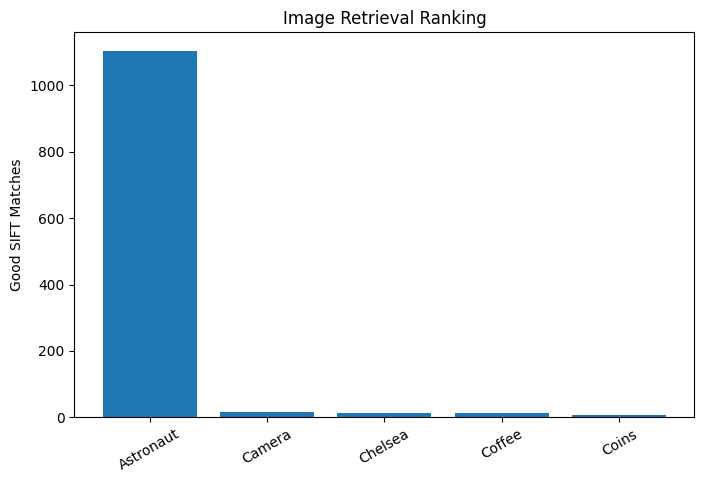

In [ ]:
database = {
    "Astronaut": data.astronaut(),
    "Coffee": data.coffee(),
    "Chelsea": data.chelsea(),
    "Camera": data.camera(),
    "Coins": data.coins()
}

query = data.astronaut()

def sift_descriptor(img):
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    sift = cv2.SIFT_create()
    kp, des = sift.detectAndCompute(img, None)
    return kp, des

qkp, qdes = sift_descriptor(query)

scores = []
bf = cv2.BFMatcher()

for name, img in database.items():
    kp, des = sift_descriptor(img)

    if des is None or qdes is None:
        good_count = 0
    else:
        matches = bf.knnMatch(qdes, des, k=2)
        good = [m for m, n in matches if m.distance < 0.75*n.distance]
        good_count = len(good)

    scores.append((name, good_count))

ranking = pd.DataFrame(scores, columns=["Image", "Good SIFT Matches"])
ranking = ranking.sort_values("Good SIFT Matches", ascending=False).reset_index(drop=True)

display(ranking)

plt.figure(figsize=(8, 5))
plt.bar(ranking["Image"], ranking["Good SIFT Matches"])
plt.xticks(rotation=30)
plt.ylabel("Good SIFT Matches")
plt.title("Image Retrieval Ranking")
plt.show()


## 10. Benchmark SIFT vs HOG on a basic object-recognition task


,Descriptor,Correct Predictions,Total Samples,Accuracy (%)
0,SIFT,15,15,100.0
1,HOG,15,15,100.0


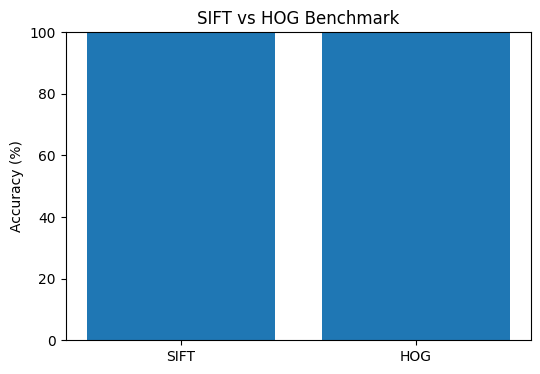

In [ ]:
# We create transformed versions of three object classes.
classes = {
    "astronaut": data.astronaut(),
    "coffee": data.coffee(),
    "chelsea": data.chelsea()
}

def make_variants(img, n=5):
    img = cv2.resize(img, (256, 256))
    variants = [img]

    for angle in [-10, 10, 20, -20]:
        M = cv2.getRotationMatrix2D((128, 128), angle, 1.0)
        variants.append(cv2.warpAffine(img, M, (256, 256)))

    return variants[:n]

samples = []
for label, img in classes.items():
    for i, variant in enumerate(make_variants(img)):
        samples.append({"label": label, "id": f"{label}_{i}", "image": variant})

def sift_signature(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    sift = cv2.SIFT_create()
    kp, des = sift.detectAndCompute(gray, None)
    return des

def sift_distance(des1, des2):
    if des1 is None or des2 is None:
        return 10**6
    matches = cv2.BFMatcher().knnMatch(des1, des2, k=2)
    good = [m for m, n in matches if m.distance < 0.75*n.distance]
    # Smaller distance is better
    return -len(good)

def hog_signature(img):
    gray = color.rgb2gray(img)
    feat = hog(
        gray,
        orientations=9,
        pixels_per_cell=(16,16),
        cells_per_block=(2,2),
        block_norm="L2-Hys"
    )
    return feat

# Precompute descriptors
for item in samples:
    item["sift"] = sift_signature(item["image"])
    item["hog"] = hog_signature(item["image"])

# Leave-one-out nearest-neighbour classification
sift_correct = 0
hog_correct = 0

for i, query_item in enumerate(samples):
    candidates = [x for j, x in enumerate(samples) if j != i]

    # SIFT: maximize number of good matches
    best_sift = min(
        candidates,
        key=lambda x: sift_distance(query_item["sift"], x["sift"])
    )
    if best_sift["label"] == query_item["label"]:
        sift_correct += 1

    # HOG: minimize Euclidean distance
    best_hog = min(
        candidates,
        key=lambda x: np.linalg.norm(query_item["hog"] - x["hog"])
    )
    if best_hog["label"] == query_item["label"]:
        hog_correct += 1

total = len(samples)
benchmark = pd.DataFrame({
    "Descriptor": ["SIFT", "HOG"],
    "Correct Predictions": [sift_correct, hog_correct],
    "Total Samples": [total, total],
    "Accuracy (%)": [100*sift_correct/total, 100*hog_correct/total]
})

display(benchmark)

plt.figure(figsize=(6, 4))
plt.bar(benchmark["Descriptor"], benchmark["Accuracy (%)"])
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("SIFT vs HOG Benchmark")
plt.show()
